<a href="https://colab.research.google.com/github/MennaAtef8/Diabetes-Data-Clustering-Using-K-Means/blob/main/Diabetes_Data_Clustering_Using_K_Means.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
dataset = pd.read_csv('diabetes.csv')
X = dataset.iloc[:,0:-1].values


In [ ]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values=0, strategy='mean')
imputer=imputer.fit(X[:, 1:6])
X[:, 1:6] = imputer.transform(X[:, 1:6])

In [ ]:

x=pd.DataFrame(X)
x.describe()



In [ ]:
dataset.iloc[: ,1:-1] = imputer.fit_transform(dataset.iloc[: ,1:-1])
dataset

In [ ]:
q1 = dataset.iloc[: ,:-1].quantile(0.25)
q3 =dataset.iloc[: ,:-1].quantile(0.75)
iqr = q3-q1
iqr


In [ ]:
dataset = dataset[~((dataset.iloc[: ,:-1] <(q1 -1.5*iqr))| (dataset.iloc[: ,:-1] >(q3+1.5*iqr))).any(axis=1)]

In [ ]:
dataset.shape

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
dataset = pd.read_csv('Mall_Customers.csv')
X =dataset.iloc[:,[3,4]].values
x =pd.DataFrame(X)


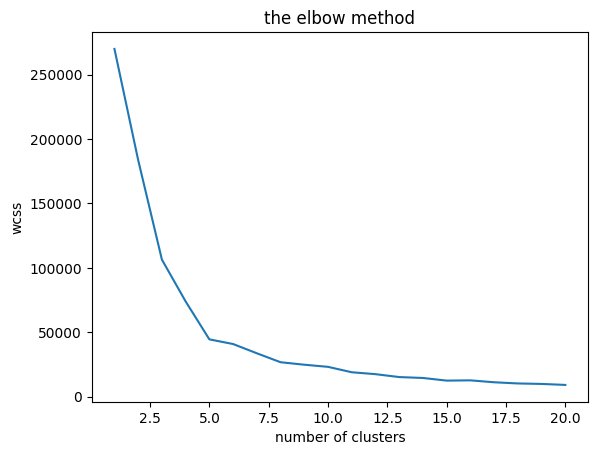

In [ ]:
wcss =[]
for i in range(1,21) :
  kmeans = KMeans(n_clusters =i , init='k-means++' ,random_state=42 )
  kmeans.fit(X)
  wcss.append(kmeans.inertia_)
plt.plot(range(1,21),wcss)
plt.title('the elbow method')
plt.xlabel('number of clusters')
plt.ylabel('wcss')
plt.show()


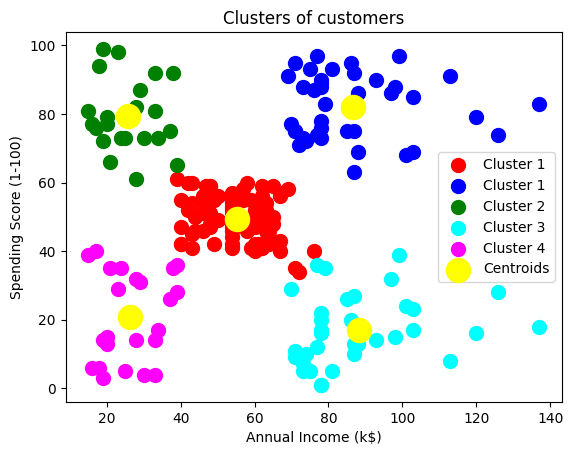

In [ ]:
kmeans = KMeans(n_clusters =5 , init='k-means++' ,random_state=42 )
y_kmeans =kmeans.fit_predict(X)
X[y_kmeans == 0]
plt.scatter(X[y_kmeans == 0, 0], X[y_kmeans == 0, 1], s = 100, c = 'red', label = 'Cluster 1')
plt.scatter(X[y_kmeans == 1, 0], X[y_kmeans == 1, 1], s = 100, c = 'blue', label = 'Cluster 1')
plt.scatter(X[y_kmeans == 2, 0], X[y_kmeans == 2, 1], s = 100, c = 'green', label = 'Cluster 2')
plt.scatter(X[y_kmeans == 3, 0], X[y_kmeans == 3, 1], s = 100, c = 'cyan', label = 'Cluster 3')
plt.scatter(X[y_kmeans == 4, 0], X[y_kmeans == 4, 1], s = 100, c = 'magenta', label = 'Cluster 4')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s = 300, c = 'yellow', label = 'Centroids')
plt.title('Clusters of customers')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.show()
